In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 図の色と見た目の設定（BLUE・ORANGE は区別したい2つ、INK は文字と基準線）。内容には関係しない
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK, "ytick.color": INK, "axes.grid": True,
    "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
})

In [2]:
rng = np.random.default_rng(34)    # 乱数の種（再現用。34 は単元番号で、意味は無い）
n = 250                            # 人数（人が決めた値。多いほど、係数の信頼区間は狭くなる）
age = rng.uniform(30, 85, n)       # 30〜85歳を一様に
sex = rng.binomial(1, 0.5, n)                       # 1 = 女性
bmi = rng.normal(23, 3.5, n) + 0.03 * (age - 55)    # 年齢とわずかに相関
# 真のモデルに、標準偏差 18 のノイズ（個人差）を足して HU を作る。回帰は、この式の係数を取り戻せるかを試される
hu = 260 - 2.0 * age + 1.5 * bmi - 15 * sex + rng.normal(0, 18, n)
bone = pd.DataFrame({"age": age, "bmi": bmi, "female": sex, "hu": hu})
print(bone.describe().round(1).loc[["count", "mean", "std", "min", "max"]])   # 各列の人数・平均・ばらつき・範囲を確認

         age    bmi  female     hu
count  250.0  250.0   250.0  250.0
mean    58.1   22.9     0.5  170.7
std     16.1    3.5     0.5   37.4
min     30.0   13.5     0.0   76.7
max     85.0   30.7     1.0  256.9


Intercept    282.429
age           -1.925
dtype: float64
傾き（年齢が1歳上がると HU がいくつ変わるか）の 95% 信頼区間: [-2.09, -1.76]
R² = 0.689   （0〜1。HU のばらつきのうち、年齢で説明できる割合）


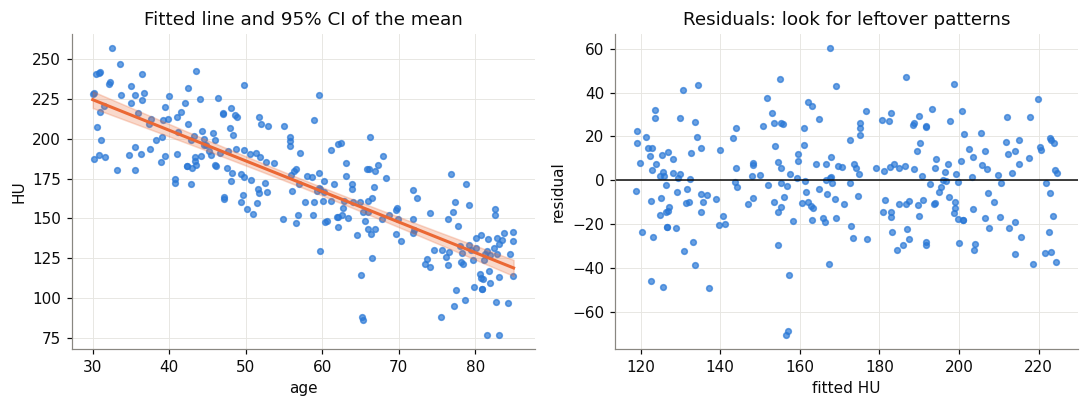

In [3]:
m1 = smf.ols("hu ~ age", data=bone).fit()     # "hu ~ age" = 「hu を age で説明する」直線。ols = 最小二乗法
print(m1.params.round(3))                      # Intercept = 切片（age=0 のときの値）、age = 傾き
print("傾き（年齢が1歳上がると HU がいくつ変わるか）の 95% 信頼区間:", m1.conf_int().loc["age"].round(2).tolist())
print(f"R² = {m1.rsquared:.3f}   （0〜1。HU のばらつきのうち、年齢で説明できる割合）")

# 図の読み方（左）: 点 = 1人。橙の線 = 当てはめた直線。橙の帯 = 「直線の位置（平均）」の95%信頼区間。
#   帯は"個々の人"の範囲ではなく、直線がどこにあるかの不確かさ。データが多い真ん中で細く、端で広がる
# 図の読み方（右）: 横 = 予測値、縦 = 残差（実測 − 予測）。0 の線のまわりに偏りなく散れば良い。帯や曲がりが見えたら、説明変数が足りない
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].scatter(bone.age, bone.hu, s=14, color=BLUE, alpha=0.7)
xs = np.linspace(30, 85, 100)       # 直線を引くための、30〜85歳を100等分した x 座標（データの範囲の内側だけ）
pred = m1.get_prediction(pd.DataFrame({"age": xs})).summary_frame(alpha=0.05)
ax[0].plot(xs, pred["mean"], color=ORANGE, lw=2)
ax[0].fill_between(xs, pred["mean_ci_lower"], pred["mean_ci_upper"], color=ORANGE, alpha=0.25)
ax[0].set(xlabel="age", ylabel="HU", title="Fitted line and 95% CI of the mean")
ax[1].scatter(m1.fittedvalues, m1.resid, s=14, color=BLUE, alpha=0.7)
ax[1].axhline(0, color=INK, lw=1)
ax[1].set(xlabel="fitted HU", ylabel="residual", title="Residuals: look for leftover patterns")
plt.tight_layout(); plt.show()

単回帰の残差の平均（性別ごと）:
female
male      6.3
female   -6.3
dtype: float64
           estimate  ci_low  ci_high   true  true inside CI
Intercept    249.91  233.32   266.50  260.0            True
age           -2.04   -2.19    -1.89   -2.0            True
bmi            1.99    1.29     2.69    1.5            True
female       -12.87  -17.57    -8.17  -15.0            True
R² = 0.749, 調整済み R² = 0.746


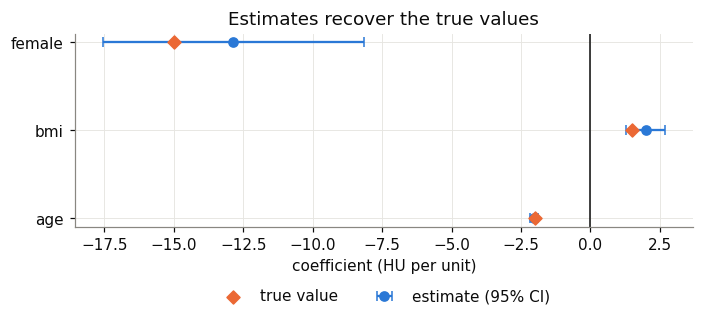

In [4]:
# 直前の「2本の帯」の確認: 単回帰の残差を、性別ごとに平均する（性別を入れていないので、ここにずれが残るはず）
print("単回帰の残差の平均（性別ごと）:")
print(m1.resid.groupby(bone.female).mean().round(1).rename({0: "male", 1: "female"}))

m2 = smf.ols("hu ~ age + bmi + female", data=bone).fit()     # 説明変数を3つに増やす（重回帰）
# 答え合わせ用の真の係数（データを作った式と同じ）。現実の研究では分からない
truth = {"Intercept": 260, "age": -2.0, "bmi": 1.5, "female": -15}
out = pd.DataFrame({"estimate": m2.params, "ci_low": m2.conf_int()[0], "ci_high": m2.conf_int()[1],
                    "true": pd.Series(truth)})
# 95%信頼区間が真の値を含むか（True なら取り戻せた。95%区間なので、20回に1回ほどは外れうる）
out["true inside CI"] = (out.ci_low <= out.true) & (out.true <= out.ci_high)
print(out.round(2))
print(f"R² = {m2.rsquared:.3f}, 調整済み R² = {m2.rsquared_adj:.3f}")   # 調整済み = 説明変数の数が増えただけの上昇を割り引いた R²

# 図の読み方: 青の点と横線 = 推定した係数と、その95%信頼区間。橙のひし形 = 真の値。ひし形が横線の中にあれば、推定は真の値を含んでいる
#   縦の黒線 = 0（効果なし）。横線が 0 をまたがなければ、効果があると言える。切片は単位が違うので描かない
fig, ax = plt.subplots(figsize=(6.5, 3.2))
names = ["age", "bmi", "female"]
y = np.arange(len(names))
ax.errorbar(out.loc[names, "estimate"], y, xerr=[out.loc[names, "estimate"] - out.loc[names, "ci_low"],
            out.loc[names, "ci_high"] - out.loc[names, "estimate"]], fmt="o", color=BLUE, capsize=3, label="estimate (95% CI)")
ax.scatter(out.loc[names, "true"], y, marker="D", color=ORANGE, zorder=3, label="true value")
ax.axvline(0, color=INK, lw=1)
ax.set_yticks(y); ax.set_yticklabels(names)
ax.set(xlabel="coefficient (HU per unit)", title="Estimates recover the true values")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2)
plt.tight_layout(); plt.show()

In [7]:
new = pd.DataFrame({"age": [60], "bmi": [23], "female": [1]})
print(round(float(m2.predict(new).iloc[0]), 1))

160.5


In [8]:
raw = load_breast_cancer(as_frame=True)
X = raw.data                      # 30個の特徴量（良性/悪性のラベルは含まない）
label = raw.target.map({0: "malignant", 1: "benign"})

pca_raw = PCA().fit(X)           # 全部の主成分を求める（標準化なし = 失敗例として見せる）
print("標準化しないとき、第1主成分が説明する割合:", round(pca_raw.explained_variance_ratio_[0], 3))
# components_[0] = 第1主成分の、各特徴量の重み（負荷量）。絶対値の大きい順に3つ見る
top = pd.Series(pca_raw.components_[0], index=X.columns).abs().sort_values(ascending=False).head(3)
print("第1主成分への寄与が大きい変数:\n", top.round(3))

標準化しないとき、第1主成分が説明する割合: 0.982
第1主成分への寄与が大きい変数:
 worst area    0.852
mean area     0.517
area error    0.056
dtype: float64


標準化したときの説明割合（第1〜5主成分）: [0.443 0.19  0.094 0.066 0.055]
第2主成分までの累積: 0.632 ／ 第5主成分までの累積: 0.847
累積 90% に必要な主成分の数: 7 （元は 30 個）


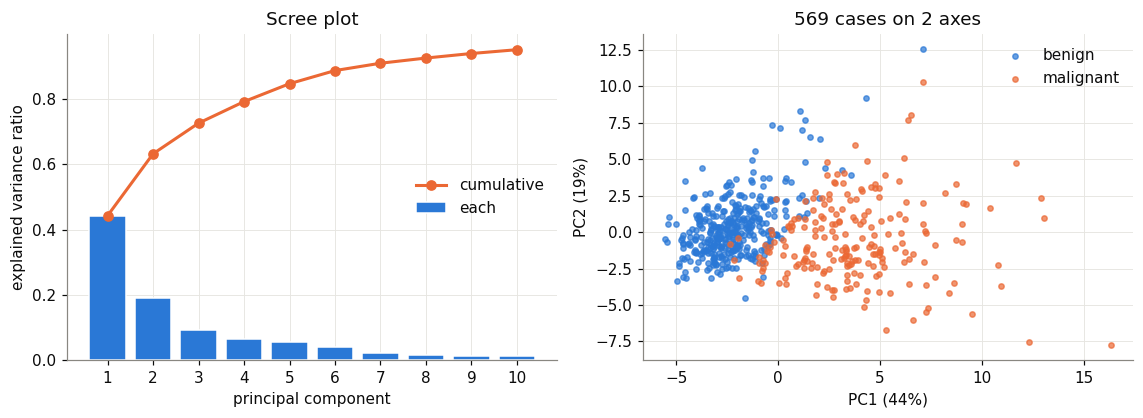

In [9]:
Z = StandardScaler().fit_transform(X)    # 各特徴量を平均0・標準偏差1にそろえる（面積だけが支配しないようにする）
pca = PCA().fit(Z)
ratio = pca.explained_variance_ratio_    # 各主成分が、全体のばらつきの何割を説明するか（合計1）
print("標準化したときの説明割合（第1〜5主成分）:", ratio[:5].round(3))
print("第2主成分までの累積:", ratio[:2].sum().round(3), "／ 第5主成分までの累積:", ratio[:5].sum().round(3))
print("累積 90% に必要な主成分の数:", int(np.argmax(np.cumsum(ratio) >= 0.9)) + 1, "（元は 30 個）")

scores = pca.transform(Z)     # 各症例を、新しい軸（主成分）の座標に直したもの
# 図の読み方（左）: スクリープロット。青の棒 = 各主成分の説明割合、橙の線 = 累積。第10主成分までを描くのは、それ以降がほぼ 0 で見えないため。
#   棒が急に低くなる所（肘）までの軸で、全体の形をおおよそ言える
# 図の読み方（右）: 1点 = 1症例を、PC1（横）と PC2（縦）の2軸に置いたもの。色（青=良性、橙=悪性）はPCAに使っていない。後から塗っただけ
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.9))
ax[0].bar(range(1, 11), ratio[:10], color=BLUE, edgecolor="white", label="each")
ax[0].plot(range(1, 11), np.cumsum(ratio)[:10], color=ORANGE, marker="o", lw=2, label="cumulative")
ax[0].set(xlabel="principal component", ylabel="explained variance ratio", title="Scree plot", xticks=range(1, 11))
ax[0].legend(frameon=False, loc="center right")
for g, c in [("benign", BLUE), ("malignant", ORANGE)]:
    m = (label == g).to_numpy()
    ax[1].scatter(scores[m, 0], scores[m, 1], s=12, color=c, alpha=0.7, label=g)
ax[1].set(xlabel=f"PC1 ({ratio[0]:.0%})", ylabel=f"PC2 ({ratio[1]:.0%})", title="569 cases on 2 axes")
ax[1].legend(frameon=False)
plt.tight_layout(); plt.show()

In [10]:
# 負荷量 = PC1 を作る各特徴量の重み。絶対値が大きいほど PC1 に効いている。正負は軸の向きだけの違い
loadings = pd.Series(pca.components_[0], index=X.columns).sort_values()
print("PC1 の負荷量の大きい上位5（符号は向きだけの意味）:")
print(loadings.reindex(loadings.abs().sort_values(ascending=False).index).head(5).round(3))

PC1 の負荷量の大きい上位5（符号は向きだけの意味）:
mean concave points     0.261
mean concavity          0.258
worst concave points    0.251
mean compactness        0.239
worst perimeter         0.237
dtype: float64


In [11]:
pca_bad = PCA().fit(X)
ratio_bad = pca_bad.explained_variance_ratio_
print("第1主成分の割合:", round(ratio_bad[0], 3))
print("累積 95% に必要な数:", int(np.argmax(np.cumsum(ratio_bad) >= 0.95)) + 1)

第1主成分の割合: 0.982
累積 95% に必要な数: 1


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK, "ytick.color": INK, "axes.grid": True,
    "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
})

In [14]:
rng = np.random.default_rng(34)
n = 250
age = rng.uniform(30, 85, n)
sex = rng.binomial(1, 0.5, n)
bmi = rng.normal(23, 3.5, n) + 0.03 * (age - 55)
hu = 260 - 2.0 * age + 1.5 * bmi - 15 * sex + rng.normal(0, 18, n)
bone = pd.DataFrame({"age": age, "bmi": bmi, "female": sex, "hu": hu})
print(bone.describe().round(1).loc[["count", "mean", "std", "min", "max"]])

         age    bmi  female     hu
count  250.0  250.0   250.0  250.0
mean    58.1   22.9     0.5  170.7
std     16.1    3.5     0.5   37.4
min     30.0   13.5     0.0   76.7
max     85.0   30.7     1.0  256.9


Intercept    282.429
age           -1.925
dtype: float64
傾き（年齢が1歳上がると HU がいくつ変わるか）の 95% 信頼区間: [-2.09, -1.76]
R² = 0.689   （0〜1。HU のばらつきのうち、年齢で説明できる割合）


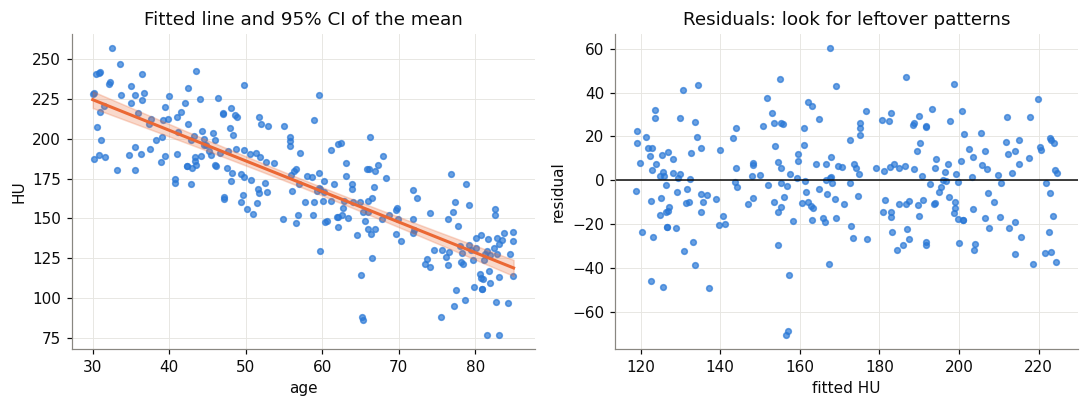

In [16]:
m1 = smf.ols("hu ~ age", data=bone).fit()
print(m1.params.round(3))
print("傾き（年齢が1歳上がると HU がいくつ変わるか）の 95% 信頼区間:", m1.conf_int().loc["age"].round(2).tolist())
print(f"R² = {m1.rsquared:.3f}   （0〜1。HU のばらつきのうち、年齢で説明できる割合）")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].scatter(bone.age, bone.hu, s=14, color=BLUE, alpha=0.7)
xs = np.linspace(30, 85, 100)
pred = m1.get_prediction(pd.DataFrame({"age": xs})).summary_frame(alpha=0.05)
ax[0].plot(xs, pred["mean"], color=ORANGE, lw=2)
ax[0].fill_between(xs, pred["mean_ci_lower"], pred["mean_ci_upper"], color=ORANGE, alpha=0.25)
ax[0].set(xlabel="age", ylabel="HU", title="Fitted line and 95% CI of the mean")
ax[1].scatter(m1.fittedvalues, m1.resid, s=14, color=BLUE, alpha=0.7)
ax[1].axhline(0, color=INK, lw=1)
ax[1].set(xlabel="fitted HU", ylabel="residual", title="Residuals: look for leftover patterns")
plt.tight_layout(); plt.show()

単回帰の残差の平均（性別ごと）:
female
male      6.3
female   -6.3
dtype: float64
           estimate  ci_low  ci_high   true  true inside CI
Intercept    249.91  233.32   266.50  260.0            True
age           -2.04   -2.19    -1.89   -2.0            True
bmi            1.99    1.29     2.69    1.5            True
female       -12.87  -17.57    -8.17  -15.0            True
R² = 0.749, 調整済み R² = 0.746


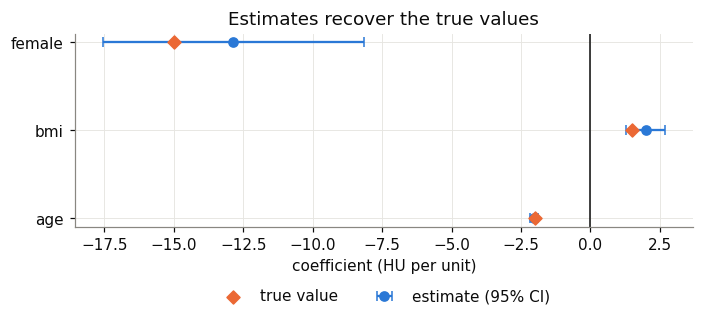

In [17]:
print("単回帰の残差の平均（性別ごと）:")
print(m1.resid.groupby(bone.female).mean().round(1).rename({0: "male", 1: "female"}))

m2 = smf.ols("hu ~ age + bmi + female", data=bone).fit()
truth = {"Intercept": 260, "age": -2.0, "bmi": 1.5, "female": -15}
out = pd.DataFrame({"estimate": m2.params, "ci_low": m2.conf_int()[0], "ci_high": m2.conf_int()[1],
                    "true": pd.Series(truth)})
out["true inside CI"] = (out.ci_low <= out.true) & (out.true <= out.ci_high)
print(out.round(2))
print(f"R² = {m2.rsquared:.3f}, 調整済み R² = {m2.rsquared_adj:.3f}")

fig, ax = plt.subplots(figsize=(6.5, 3.2))
names = ["age", "bmi", "female"]
y = np.arange(len(names))
ax.errorbar(out.loc[names, "estimate"], y, xerr=[out.loc[names, "estimate"] - out.loc[names, "ci_low"],
            out.loc[names, "ci_high"] - out.loc[names, "estimate"]], fmt="o", color=BLUE, capsize=3, label="estimate (95% CI)")
ax.scatter(out.loc[names, "true"], y, marker="D", color=ORANGE, zorder=3, label="true value")
ax.axvline(0, color=INK, lw=1)
ax.set_yticks(y); ax.set_yticklabels(names)
ax.set(xlabel="coefficient (HU per unit)", title="Estimates recover the true values")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2)
plt.tight_layout(); plt.show()

In [18]:
new = pd.DataFrame({"age": [60], "bmi": [23], "female": [1]})
print(round(float(m2.predict(new).iloc[0]), 1))

160.5


In [19]:
raw = load_breast_cancer(as_frame=True)
X = raw.data
label = raw.target.map({0: "malignant", 1: "benign"})

pca_raw = PCA().fit(X)
print("標準化しないとき、第1主成分が説明する割合:", round(pca_raw.explained_variance_ratio_[0], 3))
top = pd.Series(pca_raw.components_[0], index=X.columns).abs().sort_values(ascending=False).head(3)
print("第1主成分への寄与が大きい変数:\n", top.round(3))

標準化しないとき、第1主成分が説明する割合: 0.982
第1主成分への寄与が大きい変数:
 worst area    0.852
mean area     0.517
area error    0.056
dtype: float64


標準化したときの説明割合（第1〜5主成分）: [0.443 0.19  0.094 0.066 0.055]
第2主成分までの累積: 0.632 ／ 第5主成分までの累積: 0.847
累積 90% に必要な主成分の数: 7 （元は 30 個）


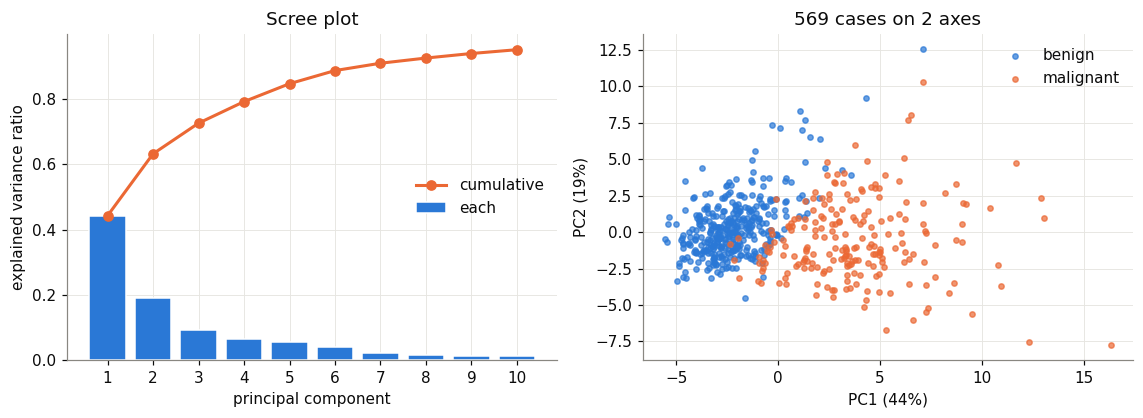

In [20]:
Z = StandardScaler().fit_transform(X)
pca = PCA().fit(Z)
ratio = pca.explained_variance_ratio_
print("標準化したときの説明割合（第1〜5主成分）:", ratio[:5].round(3))
print("第2主成分までの累積:", ratio[:2].sum().round(3), "／ 第5主成分までの累積:", ratio[:5].sum().round(3))
print("累積 90% に必要な主成分の数:", int(np.argmax(np.cumsum(ratio) >= 0.9)) + 1, "（元は 30 個）")

scores = pca.transform(Z)
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.9))
ax[0].bar(range(1, 11), ratio[:10], color=BLUE, edgecolor="white", label="each")
ax[0].plot(range(1, 11), np.cumsum(ratio)[:10], color=ORANGE, marker="o", lw=2, label="cumulative")
ax[0].set(xlabel="principal component", ylabel="explained variance ratio", title="Scree plot", xticks=range(1, 11))
ax[0].legend(frameon=False, loc="center right")
for g, c in [("benign", BLUE), ("malignant", ORANGE)]:
    m = (label == g).to_numpy()
    ax[1].scatter(scores[m, 0], scores[m, 1], s=12, color=c, alpha=0.7, label=g)
ax[1].set(xlabel=f"PC1 ({ratio[0]:.0%})", ylabel=f"PC2 ({ratio[1]:.0%})", title="569 cases on 2 axes")
ax[1].legend(frameon=False)
plt.tight_layout(); plt.show()

In [21]:
loadings = pd.Series(pca.components_[0], index=X.columns).sort_values()
print("PC1 の負荷量の大きい上位5（符号は向きだけの意味）:")
print(loadings.reindex(loadings.abs().sort_values(ascending=False).index).head(5).round(3))

PC1 の負荷量の大きい上位5（符号は向きだけの意味）:
mean concave points     0.261
mean concavity          0.258
worst concave points    0.251
mean compactness        0.239
worst perimeter         0.237
dtype: float64


In [22]:
pca_bad = PCA().fit(X)
ratio_bad = pca_bad.explained_variance_ratio_
print("第1主成分の割合:", round(ratio_bad[0], 3))
print("累積 95% に必要な数:", int(np.argmax(np.cumsum(ratio_bad) >= 0.95)) + 1)

第1主成分の割合: 0.982
累積 95% に必要な数: 1


In [23]:
Z2 = StandardScaler().fit_transform(X)
pca_fixed = PCA().fit(Z2)
ratio_fixed = pca_fixed.explained_variance_ratio_
print("第1主成分の割合:", round(ratio_fixed[0], 3))
print("累積 95% に必要な数:", int(np.argmax(np.cumsum(ratio_fixed) >= 0.95)) + 1)

第1主成分の割合: 0.443
累積 95% に必要な数: 10
